# Next-Word Text Generation with Simple RNN, Bidirectional RNN, LSTM and GRU
**Dataset:** Grimms' Fairy Tales – Project Gutenberg eBook #2591 – https://www.gutenberg.org/ebooks/2591

On Kaggle, turn on **GPU** and **Internet** in the notebook settings, then click *Run All*.

In [5]:
import re, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

## 1. Dataset

In [6]:
url = "https://www.gutenberg.org/cache/epub/2591/pg2591.txt"
text = urllib.request.urlopen(url).read().decode("utf-8")

# keep only the book (remove the Project Gutenberg header and footer)
start = text.find("*** START OF")
start = text.find("\n", start) + 1
end = text.find("*** END OF")
text = text[start:end]

print("Characters:", len(text))
print(text[2000:2600])

Characters: 530055
-SKIN
     SNOW-WHITE AND ROSE-RED




THE BROTHERS GRIMM FAIRY TALES




THE GOLDEN BIRD


A certain king had a beautiful garden, and in the garden stood a tree
which bore golden apples. These apples were always counted, and about
the time when they began to grow ripe it was found that every night one
of them was gone. The king became very angry at this, and ordered the
gardener to keep watch all night under the tree. The gardener set his
eldest son to watch; but about twelve o’clock he fell asleep, and in
the morning another of the apples was missing. Then the second son 


## 2. Preprocessing and input–target sequences

In [7]:
# lower-case and keep only letters and spaces
clean = re.sub(r"[^a-z\s]", " ", text.lower())
words = clean.split()

vocab = sorted(set(words))
word_to_id = {w: i + 1 for i, w in enumerate(vocab)}   # 0 is reserved for padding
id_to_word = {i: w for w, i in word_to_id.items()}
vocab_size = len(vocab) + 1

print("Total words :", len(words))
print("Unique words:", len(vocab))
print("Most common :", pd.Series(words).value_counts().head(10).to_dict())

Total words : 102114
Unique words: 4746
Most common : {'the': 7044, 'and': 5481, 'to': 2669, 'he': 2093, 'a': 1920, 'was': 1384, 'of': 1371, 'it': 1310, 'she': 1232, 'you': 1192}


In [8]:
SEQ_LEN = 10   # use 10 words to predict the next word

ids = np.array([word_to_id[w] for w in words])
X = np.array([ids[i:i + SEQ_LEN] for i in range(len(ids) - SEQ_LEN)])
y = ids[SEQ_LEN:]

# first 90% for training, last 10% for testing
split = int(0.9 * len(X))
X_train, y_train = X[:split], y[:split]
X_test, y_test = X[split:], y[split:]

print("Training sequences:", len(X_train), "| Test sequences:", len(X_test))
print("Example input :", " ".join(id_to_word[i] for i in X[0]))
print("Example target:", id_to_word[y[0]])

Training sequences: 91893 | Test sequences: 10211
Example input : grimms fairy tales by jacob grimm and wilhelm grimm preparer
Example target: s


## 3. Models
All four models have the same structure. Only the recurrent layer is different:

`Embedding(100) → recurrent layer (128 units) → Dense(vocab_size, softmax)`

- **Simple RNN**: a basic recurrent layer.
- **Bidirectional RNN**: a Simple RNN that reads the input words forwards and backwards.
- **LSTM**: uses gates and a cell state to remember longer context.
- **GRU**: a simpler gated layer than the LSTM.

In [9]:
def build_model(name):
    rnn = {
        "SimpleRNN": layers.SimpleRNN(128),
        "BiRNN": layers.Bidirectional(layers.SimpleRNN(128)),
        "LSTM": layers.LSTM(128),
        "GRU": layers.GRU(128),
    }[name]
    model = keras.Sequential([
        keras.Input(shape=(SEQ_LEN,)),
        layers.Embedding(vocab_size, 100),
        rnn,
        layers.Dense(vocab_size, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

## 4. Training (same settings for all models)

In [10]:
EPOCHS = 15
BATCH_SIZE = 128

models, histories, times = {}, {}, {}
for name in ["SimpleRNN", "BiRNN", "LSTM", "GRU"]:
    print("\nTraining", name)
    model = build_model(name)
    start_time = time.time()
    history = model.fit(X_train, y_train, validation_data=(X_test, y_test),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2)
    times[name] = time.time() - start_time
    models[name] = model
    histories[name] = history.history


Training SimpleRNN


I0000 00:00:1792142405.645730      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792142405.649574      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/15


I0000 00:00:1792142411.021034     142 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


718/718 - 8s - 11ms/step - accuracy: 0.0825 - loss: 6.0069 - val_accuracy: 0.1085 - val_loss: 5.7344
Epoch 2/15
718/718 - 2s - 3ms/step - accuracy: 0.1229 - loss: 5.3095 - val_accuracy: 0.1294 - val_loss: 5.4112
Epoch 3/15
718/718 - 3s - 3ms/step - accuracy: 0.1437 - loss: 4.9343 - val_accuracy: 0.1401 - val_loss: 5.3115
Epoch 4/15
718/718 - 2s - 3ms/step - accuracy: 0.1624 - loss: 4.6765 - val_accuracy: 0.1447 - val_loss: 5.2903
Epoch 5/15
718/718 - 3s - 3ms/step - accuracy: 0.1775 - loss: 4.4668 - val_accuracy: 0.1457 - val_loss: 5.3082
Epoch 6/15
718/718 - 2s - 3ms/step - accuracy: 0.1916 - loss: 4.2825 - val_accuracy: 0.1457 - val_loss: 5.3401
Epoch 7/15
718/718 - 2s - 3ms/step - accuracy: 0.2058 - loss: 4.1155 - val_accuracy: 0.1465 - val_loss: 5.3738
Epoch 8/15
718/718 - 2s - 3ms/step - accuracy: 0.2202 - loss: 3.9603 - val_accuracy: 0.1464 - val_loss: 5.4143
Epoch 9/15
718/718 - 2s - 3ms/step - accuracy: 0.2358 - loss: 3.8143 - val_accuracy: 0.1447 - val_loss: 5.4654
Epoch 10/15

## 5. Evaluation: loss, perplexity, accuracy and training time

In [11]:
results = []
for name, model in models.items():
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    results.append({"Model": name, "Test loss": loss, "Perplexity": np.exp(loss),
                    "Accuracy": acc, "Training time (s)": times[name]})
results = pd.DataFrame(results).round(3)
results

,Model,Test loss,Perplexity,Accuracy,Training time (s)
0,SimpleRNN,5.876,356.438,0.134,42.888
1,BiRNN,6.331,561.984,0.118,51.687
2,LSTM,5.606,272.173,0.150,64.937
3,GRU,5.668,289.465,0.143,61.183


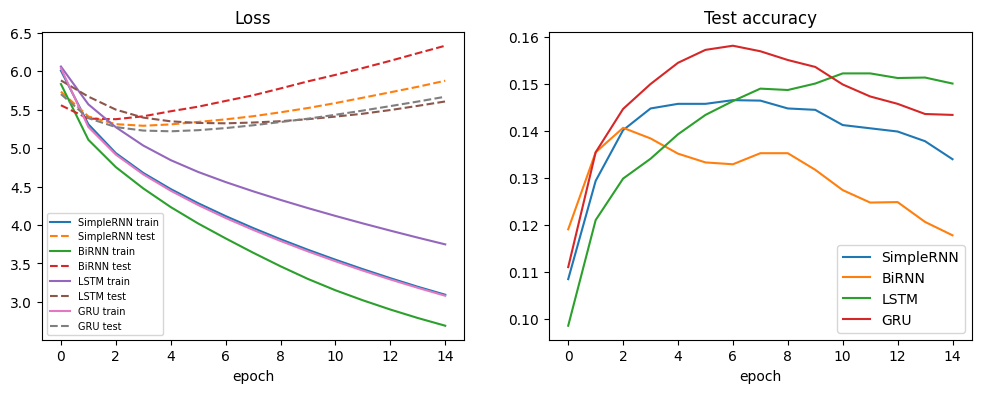

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    ax[0].plot(h["loss"], label=name + " train")
    ax[0].plot(h["val_loss"], "--", label=name + " test")
    ax[1].plot(h["val_accuracy"], label=name)
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=7)
ax[1].set_title("Test accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

## 6. Text generation with different temperatures

In [13]:
def generate(model, seed, n_words=30, temperature=1.0):
    result = seed.lower().split()
    for _ in range(n_words):
        seq = [word_to_id.get(w, 0) for w in result][-SEQ_LEN:]
        seq = [0] * (SEQ_LEN - len(seq)) + seq          # pad short seeds on the left
        probs = model.predict(np.array([seq]), verbose=0)[0]
        probs = np.log(probs + 1e-10) / temperature     # apply temperature
        probs = np.exp(probs) / np.sum(np.exp(probs))
        next_id = np.random.choice(len(probs), p=probs)
        if next_id == 0:                                # skip the padding token
            continue
        result.append(id_to_word[next_id])
    return " ".join(result)

seeds = ["once upon a time there was a king who had",
         "the little tailor went into the forest and"]
temperatures = [0.5, 1.0, 1.5]

samples = []
for seed in seeds:
    for t in temperatures:
        for name, model in models.items():
            text_out = generate(model, seed, temperature=t)
            samples.append({"Seed": seed, "Temperature": t, "Model": name, "Generated text": text_out})
            print(f"[{name} | T={t}] {text_out}\n")
samples = pd.DataFrame(samples)

[SimpleRNN | T=0.5] once upon a time there was a king who had no sorrow and meek and the father saw that the bird was the king s daughter and sat down down on a couch and the soldier fell into the castle

[BiRNN | T=0.5] once upon a time there was a king who had not a man who was so serious that two one could have a long long they were gone on and took a very unhappy to the great hunger and said

[LSTM | T=0.5] once upon a time there was a king who had been at the fox and the king said he would not be a man who was so beautiful and he went to the castle and said to himself what he

[GRU | T=0.5] once upon a time there was a king who had a son and the wedding was to be a chandelier in the night the thought of the little house he had a son and said to himself he will be

[SimpleRNN | T=1.0] once upon a time there was a king who had striding up hurts bed buried between the wand and the horse fell behind him turned full of the hearse turned turned instantly and fell asleep again the next d

### Simple measures of diversity and repetition
- **Unique word ratio**: unique words divided by total words. Higher means more diverse text.
- **Repetition rate**: the share of word pairs that have already appeared earlier in the text. Higher means more repetitive text.

In [14]:
def unique_ratio(s):
    w = s.split()
    return len(set(w)) / len(w)

def repetition_rate(s):
    w = s.split()
    pairs = list(zip(w, w[1:]))
    return 1 - len(set(pairs)) / len(pairs)

samples["Unique word ratio"] = samples["Generated text"].apply(unique_ratio)
samples["Repetition rate"] = samples["Generated text"].apply(repetition_rate)
samples.groupby(["Model", "Temperature"])[["Unique word ratio", "Repetition rate"]].mean().round(3)

Unique word ratio  Repetition rate
Model     Temperature                                    
BiRNN     0.5                      0.782            0.000
          1.0                      0.846            0.000
          1.5                      0.872            0.000
GRU       0.5                      0.720            0.038
          1.0                      0.871            0.013
          1.5                      0.897            0.000
LSTM      0.5                      0.693            0.014
          1.0                      0.796            0.013
          1.5                      0.871            0.000
SimpleRNN 0.5                      0.679            0.026
          1.0                      0.782            0.014
          1.5                      0.886            0.000